## OFDM TESTBENCH

This notebook sends interleaved real/imaginary OFDM input samples to the AXI4 memory-mapped OFDM receiver and compares decoded QPSK outputs against out.gold.dat.

In [140]:
from pynq import Overlay, allocate
import numpy as np
# from pynq import Xlnk
from pynq.lib import dma
from scipy.linalg import dft
import matplotlib.pyplot as plt
import time
from pathlib import Path
import pynq
import pynq.ps

In [141]:
ol = Overlay('ofdm.bit')

print("IP blocks:")
print(list(ol.ip_dict.keys()))

print("\nHierarchies:")
print(list(ol.hierarchy_dict.keys()))

IP blocks:
['ofdm_receiver_axi_0', 'processing_system7_0']

Hierarchies:
[]


## Input Parameters and Files

In [142]:
NUM_SAMPLES = 35000
FFT_SIZE = 1024

# real and imaginary sample data .dat file
input_file = Path("input.dat")
# golden output file used in test bench
golden_file = Path("out.gold.dat")

input_complex_all = np.loadtxt(input_file, dtype=np.float32)
golden_output_all = np.loadtxt(golden_file, dtype=np.uint32)

inp_R = np.empty([NUM_SAMPLES,], dtype=np.float32)
inp_I = np.empty([NUM_SAMPLES,], dtype=np.float32)

for i in range(NUM_SAMPLES):
    inp_R[i] = input_complex[i][0]
    inp_I[i] = input_complex[i][1]
    
input_buffer = allocate(shape=(2 * NUM_SAMPLES,),dtype=np.float32)
output_buffer = allocate(shape=(NUM_SAMPLES,),dtype=np.uint32)

for i in range(NUM_SAMPLES):
    input_buffer[2 * i] = inp_R[i]
    input_buffer[2 * i + 1] = inp_I[i]

# Clear output memory before hardware execution.
output_buffer[:] = 0

print("Input buffer physical address:  0x{:016X}".format(input_buffer.physical_address))

print("Output buffer physical address: 0x{:016X}".format(output_buffer.physical_address))


## Helper Function for 64-Bit AXI-Lite Pointer Registers

def write_64bit_address(ip, lower_offset, address):
    lower_bits = address & 0xFFFFFFFF
    upper_bits = (address >> 32) & 0xFFFFFFFF

    ip.write(lower_offset, lower_bits)
    ip.write(lower_offset + 4, upper_bits)

Input buffer physical address:  0x0000000015900000
Output buffer physical address: 0x00000000158C0000


In [143]:
# Flush CPU-written input data to DDR before PL reads it.
input_buffer.flush()

# Input-buffer physical address
write_64bit_address(ofdm_ip, 0x10, input_buffer.physical_address)

# Output-buffer physical address
write_64bit_address(ofdm_ip, 0x1C, output_buffer.physical_address)

# Number of complex OFDM samples
ofdm_ip.write(0x28, NUM_SAMPLES)


## Start Hardware and Wait for Completion

TIMEOUT_SECONDS = 10.0

t_start = time.time()

# CTRL bit 0 = ap_start
ofdm_ip.write(0x00, 1)

while (ofdm_ip.read(0x00) & 0x02) == 0:
    if (time.time() - t_start) > TIMEOUT_SECONDS:
        raise TimeoutError("Timed out waiting for OFDM hardware completion.")

hardware_time = time.time() - t_start

# Make PL-written output data visible to the CPU.
output_buffer.invalidate()

print("Hardware execution time: ", hardware_time, "seconds")


## Copy Hardware Output from CMA Buffer
hardware_output = np.empty([NUM_SAMPLES,], dtype=np.uint32)

for i in range(NUM_SAMPLES):
    hardware_output[i] = output_buffer[i]

Hardware execution time:  0.09315633773803711 seconds


## Verifying Functionality 

In [144]:
# pre-allocate arrays
symbol_error = np.zeros(NUM_SAMPLES)
ind = np.arange(NUM_SAMPLES)
symbol_rmse = np.zeros(NUM_SAMPLES)

# calculates symbol error
for i in range(NUM_SAMPLES):
    symbol_error[i] = abs(int(hardware_output[i]) - int(golden_output[i]))

sum_sq_symbol = 0

# Symbol RMSE calculation
for i in range(NUM_SAMPLES):
    sum_sq_symbol = sum_sq_symbol + (symbol_error[i] * symbol_error[i])
    symbol_rmse[i] = np.sqrt(sum_sq_symbol / (i + 1))

miss_match_cnt = 0

# finds if there is a mismatch
for i in range(NUM_SAMPLES):
    if golden_output[i] != hardware_output[i]:
        miss_match_cnt = miss_match_cnt + 1

# print output calculations
print("Symbol RMSE: ", symbol_rmse[NUM_SAMPLES - 1])
print("Number of mismatches: ", miss_match_cnt)

# condition statements
if miss_match_cnt == 0:
    print("PASS: All hardware outputs match the golden output.")
else:
    print("FAIL: Hardware output does not match the golden output.")
    print("\nFirst output mismatches:")

    printed_mismatches = 0

    # if there is an error prints where error occurred
    for i in range(NUM_SAMPLES):
        if golden_output[i] != hardware_output[i]:
            print("Index: {} \tGolden: {} \tHardware: {}".format(i, golden_output[i], hardware_output[i]))
            printed_mismatches = printed_mismatches + 1
            if printed_mismatches == 20:
                break

Symbol RMSE:  0.0
Number of mismatches:  0
PASS: All hardware outputs match the golden output.


## Displaying Error and Output

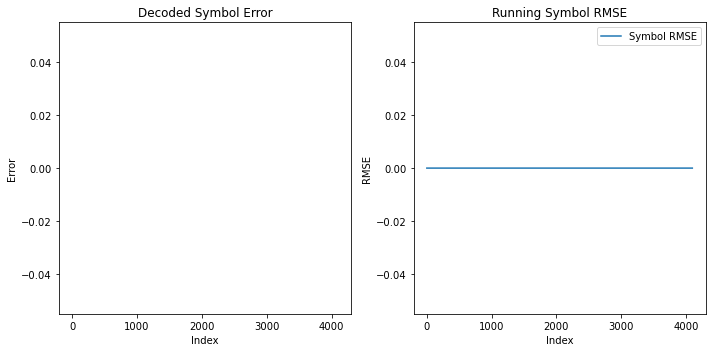

In [145]:
PLOT_SAMPLES = min(NUM_SAMPLES, 4096)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)

plt.bar(ind[0:PLOT_SAMPLES], symbol_error[0:PLOT_SAMPLES])

plt.title("Decoded Symbol Error")
plt.xlabel("Index")
plt.ylabel("Error")
plt.tight_layout()

plt.subplot(1, 2, 2)

plt.plot(ind[0:PLOT_SAMPLES], symbol_rmse[0:PLOT_SAMPLES], label="Symbol RMSE")

plt.title("Running Symbol RMSE")
plt.xlabel("Index")
plt.ylabel("RMSE")
plt.legend()
plt.tight_layout()

plt.show()


## Displaying Hardware and Golden Output

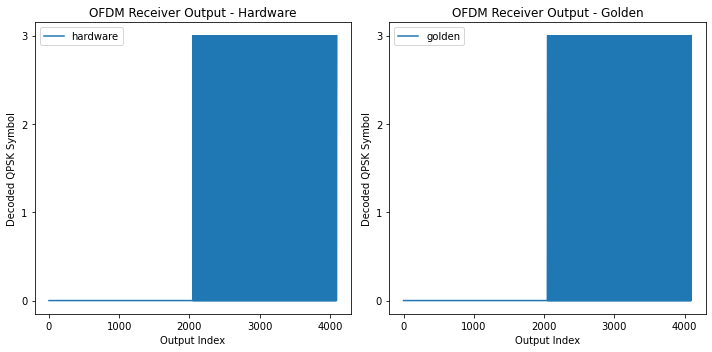

In [146]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)

plt.plot(ind[0:PLOT_SAMPLES], hardware_output[0:PLOT_SAMPLES], label="hardware")

plt.title("OFDM Receiver Output - Hardware")
plt.xlabel("Output Index")
plt.ylabel("Decoded QPSK Symbol")
plt.yticks([0, 1, 2, 3])
plt.legend()
plt.tight_layout()

plt.subplot(1, 2, 2)

plt.plot(ind[0:PLOT_SAMPLES], golden_output[0:PLOT_SAMPLES], label="golden")

plt.title("OFDM Receiver Output - Golden")
plt.xlabel("Output Index")
plt.ylabel("Decoded QPSK Symbol")
plt.yticks([0, 1, 2, 3])
plt.legend()
plt.tight_layout()

plt.show()


## Displaying Input Real and Imaginary Components

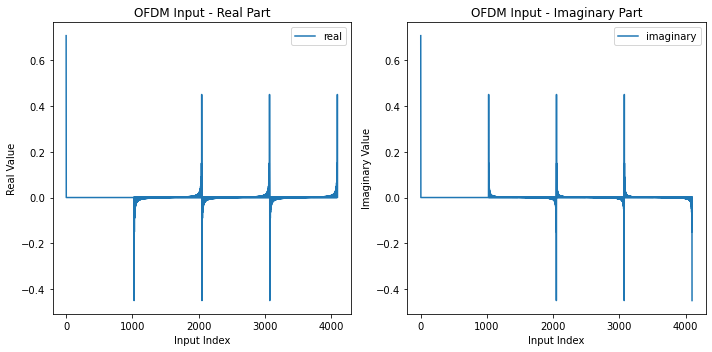

In [147]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)

plt.plot(ind[0:PLOT_SAMPLES], inp_R[0:PLOT_SAMPLES], label="real")

plt.title("OFDM Input - Real Part")
plt.xlabel("Input Index")
plt.ylabel("Real Value")
plt.legend()
plt.tight_layout()

plt.subplot(1, 2, 2)

plt.plot(
    ind[0:PLOT_SAMPLES],
    inp_I[0:PLOT_SAMPLES],
    label="imaginary"
)

plt.title("OFDM Input - Imaginary Part")
plt.xlabel("Input Index")
plt.ylabel("Imaginary Value")
plt.legend()
plt.tight_layout()

plt.show()




## Displaying Input Constellation

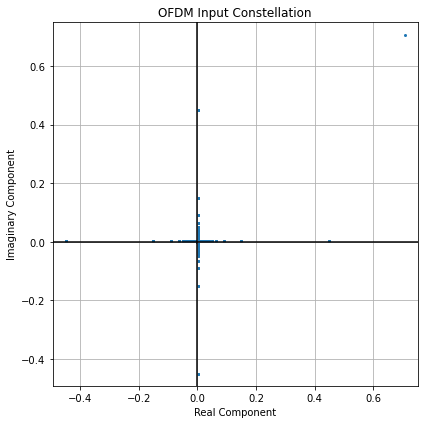

In [148]:
## Displaying Input Constellation
CONSTELLATION_SAMPLES = min(NUM_SAMPLES, 5000)

plt.figure(figsize=(6, 6))

plt.scatter(inp_R[0:CONSTELLATION_SAMPLES], inp_I[0:CONSTELLATION_SAMPLES], s=4)

plt.title("OFDM Input Constellation")
plt.xlabel("Real Component")
plt.ylabel("Imaginary Component")
plt.axhline(0, color="black")
plt.axvline(0, color="black")
plt.grid(True)
plt.axis("equal")
plt.tight_layout()

plt.show()